In [92]:
from pathlib import Path

#import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
#import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: c:\Users\flavs\Documents\ml-course\data


In [93]:
students = pd.read_csv(DATA_DIR/"data_studentlist.csv")
students.head()

,Name,Gender,Age,Grade,Absence,Bloodtype,Height,Weight
0,Jared Diamond,M,23,3,Y,O,165.3,68.2
1,Sarah O'Donnel,F,22,2,N,AB,170.1,53.0
2,Brian Martin,M,24,4,N,B,175.0,80.1
3,David Hassel,M,23,3,N,AB,182.1,85.7
4,Clara Rodriquez,F,20,1,Y,A,168.0,49.5


In [94]:
#sacar la altura media
students_man = students[students["Gender"]=="M"]
students_man_mean = students_man["Height"].mean()
print(f"La altura promedio de los estudiantes varones es: {students_man_mean.round(2)}cm")

students_woman = students[students["Gender"]=="F"]
students_woman_mean = students_woman["Height"].mean()
print(f"La altura promedio de las estudiantes mujeres es: {students_woman_mean.round(2)}cm")

La altura promedio de los estudiantes varones es: 172.41cm
La altura promedio de las estudiantes mujeres es: 166.64cm


In [95]:
students_man_weight = students_man["Weight"].mean()
students_woman_weight = students_woman["Weight"].mean()

print(f"El peso promedio de los estudiantes varones es: {students_man_weight.round(2)}kg")
print(f"El peso promedio de las estudiantes mujeres es: {students_woman_weight.round(2)}kg")

El peso promedio de los estudiantes varones es: 68.5kg
El peso promedio de las estudiantes mujeres es: 50.44kg


In [96]:
students_man_max = students_man["Height"].max()
students_woman_min = students_woman["Height"].min()

print(f"La altura maxima de los estudiantes varones es: {students_man_max.round(2)}cm")
print(f"La altura minima de las estudiantes mujeres es: {students_woman_min.round(2)}cm")


La altura maxima de los estudiantes varones es: 182.1cm
La altura minima de las estudiantes mujeres es: 155.2cm


In [97]:
students_min_weight = students_man[students_man["Height"]>175]
print(students_min_weight["Weight"].min())
students_max_weight = students_woman[students_woman["Height"]<160]
print(students_max_weight["Weight"].max())

61.3
45.3


In [98]:
students_grades = students[students["Absence"] != "Y"]
print(students_grades["Grade"].mean().round(2))
students_grades = students[students["Absence"] == "Y"]
print(students_grades["Grade"].mean().round(2))

2.08
3.0


In [99]:
students_blood = students[(students["Gender"] == "M") & ((students["Bloodtype"] == "A") | (students["Bloodtype"] == "AB"))]
print(students_blood["Height"].mean().round(2))
students_age = students[(students["Absence"] == "Y") &(students["Grade"]>=3)]
print(students_grades["Grade"].mean().round(2))

173.38
3.0


In [100]:
Census = pd.read_csv(DATA_DIR/"data_census.csv")
Census.head()


,Province Code,City Code,Population,Households,Person's Household,Gender Ratio
0,109,1001,"10,078,850","4,197,478",2.40,0.97
1,109,1188,"155,695","72,882",2.14,0.98
2,109,1189,"126,817","59,614",2.13,1.00
3,109,1158,"235,186","108,138",2.17,0.94
4,109,1105,"298,145","126,915",2.35,0.99


In [101]:
Census["Population"] = (Census["Population"]
                .str.replace(",", "", regex=False))
Census["Population"] = pd.to_numeric(Census["Population"])
Census["Households"] = (Census["Households"]
                .str.replace(",", "", regex=False))
Census["Households"] = pd.to_numeric(Census["Households"])
PC_Census = Census[(Census["Province Code"] == 115) | (Census["Province Code"] == 116)]
print(PC_Census["Population"].sum())

5970327


In [102]:
M_Census = Census[Census["Gender Ratio"] > 1]
M_Census.groupby("City Code")["Population"].mean()

City Code
1001    2.613991e+06
1002    6.169300e+04
1007    8.677100e+04
1009    6.738300e+04
1010    2.528230e+05
            ...     
1230    6.925600e+04
1237    7.040000e+04
1238    5.682650e+05
1240    2.679000e+04
1241    4.557300e+04
Name: Population, Length: 115, dtype: float64

In [103]:
L_Census = M_Census[M_Census["Households"] < 2]
L_Census.head()

,Province Code,City Code,Population,Households,Person's Household,Gender Ratio


In [108]:
H_Census = Census["Households"].sort_values(ascending=False)
H_Census.loc[:10]

83     4829521
0      4197478
26     1430441
254    1356430
228    1160150
        ...   
45      143591
190     141829
9       141325
173     139294
10      137260
Name: Households, Length: 76, dtype: int64

In [110]:
Ventas = pd.read_csv(DATA_DIR/"data_sales.csv")
Ventas.info()
Ventas.head()

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        43 non-null     str    
 1   Region      43 non-null     str    
 2   Item        43 non-null     str    
 3   Unit Price  43 non-null     float64
 4   Units       43 non-null     int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 1.8 KB


,Date,Region,Item,Unit Price,Units
0,04-Jul-14,East,Pen Set,4.99,62
1,12-Jul-14,East,Binder,1.99,29
2,21-Jul-14,Central,Pen Set,12.49,55
3,29-Jul-14,East,Binder,19.99,81
4,07-Aug-14,Central,Pen Set,23.95,42


In [111]:
Ventas["Amount"] = Ventas["Unit Price"] * Ventas["Units"]
Ventas.head()

,Date,Region,Item,Unit Price,Units,Amount
0,04-Jul-14,East,Pen Set,4.99,62,309.38
1,12-Jul-14,East,Binder,1.99,29,57.71
2,21-Jul-14,Central,Pen Set,12.49,55,686.95
3,29-Jul-14,East,Binder,19.99,81,1619.19
4,07-Aug-14,Central,Pen Set,23.95,42,1005.90


In [114]:
Ventas.groupby("Region")["Unit Price"].mean()

Region
Central    18.018750
East        9.143846
West       53.658333
Name: Unit Price, dtype: float64

In [126]:
pd.pivot_table(Ventas, values="Unit Price", index="Region",
               aggfunc="mean")

,Unit Price
Region,
Central,18.018750
East,9.143846
West,53.658333


In [129]:
pd.pivot_table(Ventas, values="Unit Price", index="Units", columns= "Region",
               aggfunc="mean").head()

Region,Central,East,West
Units,,,
2,125.00,NaN,NaN
3,NaN,NaN,275.00
4,NaN,4.99,NaN
5,125.00,NaN,NaN
7,1.29,NaN,19.99


In [130]:
pd.pivot_table(Ventas, values="Units", index="Region", columns= "Item",
               aggfunc="sum").head()

Item,Binder,Desk,Pen,Pen Set,Pencil
Region,,,,,
Central,424.0,7.0,27.0,243.0,498.0
East,234.0,NaN,175.0,152.0,130.0
West,64.0,3.0,76.0,NaN,88.0


In [133]:
pd.pivot_table(Ventas, values="Amount", index="Region", columns= "Item",
               aggfunc="sum").fillna(0).head()



Item,Binder,Desk,Pen,Pen Set,Pencil
Region,,,,,
Central,5762.63,875.0,539.73,2421.39,1540.32
East,2535.66,0.0,1354.25,1748.48,363.70
West,1279.36,825.0,151.24,0.00,231.12


In [136]:
import matplotlib.pyplot as plt
coffee_shop = pd.read_csv(DATA_DIR/"data_coffeeshop.csv")
coffee_shop.info()
coffee_shop.head()

<class 'pandas.DataFrame'>
RangeIndex: 43182 entries, 0 to 43181
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year of Start  43163 non-null  float64
 1   Current State  43163 non-null  str    
 2   Size of Site   43163 non-null  float64
dtypes: float64(2), str(1)
memory usage: 1012.2 KB


,Year of Start,Current State,Size of Site
0,2008.0,In,20.80
1,2010.0,In,212.72
2,2013.0,In,20.04
3,2012.0,In,64.17
4,2002.0,Out,11.40


42678    1964.0
21255    1964.0
26654    1966.0
37099    1966.0
41426    1967.0
Name: Year of Start, dtype: float64


C:\Users\flavs\AppData\Local\Temp\ipykernel_27832\3041883112.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


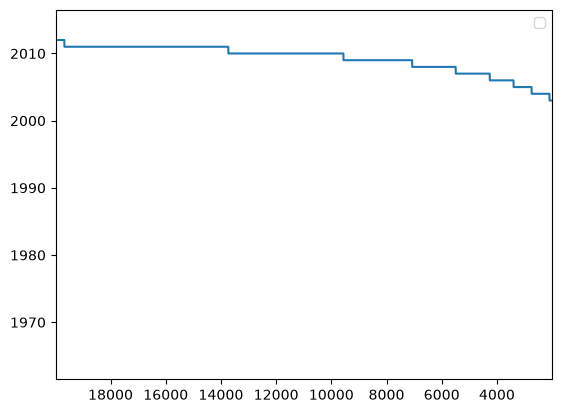

In [155]:
Year_of_Start = coffee_shop["Year of Start"].sort_values(ascending=True)
print(Year_of_Start.head())

fig, ax = plt.subplots()
time = range(0,len(Year_of_Start))
ax.plot(time, Year_of_Start)
ax.legend()
plt.xlim(19987,2014)
plt.show()

22216    1967.0
41426    1967.0
10884    1970.0
18674    1970.0
21302    1971.0
Name: Year of Start, dtype: float64
42678    1964.0
21255    1964.0
37099    1966.0
26654    1966.0
7230     1967.0
Name: Year of Start, dtype: float64


C:\Users\flavs\AppData\Local\Temp\ipykernel_27832\396323979.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


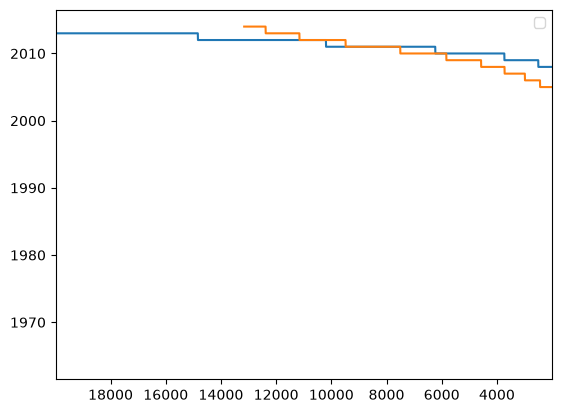

In [ ]:
In_df = coffee_shop[coffee_shop["Current State"] == "In"]
Out_df = coffee_shop[coffee_shop["Current State"] == "Out"]
In_df = In_df["Year of Start"].sort_values(ascending=True)
Out_df = Out_df["Year of Start"].sort_values(ascending=True)
print(In_df.head())
print(Out_df.head())

fig, ax = plt.subplots()
ax.plot(range(0,len(In_df)), In_df)
ax.plot(range(0,len(Out_df)),Out_df)
ax.legend()
plt.xlim(19987,2014)
plt.show()

